<table style="border:0;width:100%;border-collapse:collapse"><tr style="border:0"><td style="border:0;width:105px;vertical-align:middle"><img src="../Imagenes/logo-final-ap.png" width="90"/></td><td style="border:0;vertical-align:middle"><span style="font-size:32px;font-weight:700;color:#bd232b">Aprendizaje Profundo</span></td></tr></table>

[https://github.com/AprendizajeProfundo](https://github.com/AprendizajeProfundo)

# <span style="color:#174ea6">Cuaderno 107A · Meta-learning y adaptación rápida a nuevas condiciones operativas</span>

**Sesión 4 · Primera lección · 55 minutos en clase (ampliaciones para estudio autónomo)**

**Autores:** Alvaro Montenegro · Daniel Montenegro · Pilar Montenegro  
**Docente:** Alvaro Montenegro, [ammontenegrod@gmail.com](mailto:ammontenegrod@gmail.com),    
**Institución:** Universidad de los Andes - Ecopetrol  
**Edición docente:** 107 · Octubre de 2026  
**Licencia del contenido y código originales de esta edición:** MIT (véase sección final).

> **Pregunta rectora.** ¿Cómo preparar un modelo para que aprenda rápidamente una tarea nueva, sin confundir adaptación genuina con haber visto antes esa tarea?

**Contexto:** transporte de hidrocarburos.  
**Propósito:** entender qué es una tarea, qué significa adaptarse y qué aprende Reptile.  

**Fuentes directas:** programa aprobado de la sesión 4; cuadernos 103 y 104 (gradientes, entrenamiento y evaluación); documentación conceptual de Hydro-Lab S2.11 y arquitectura G2.4. El experimento es **sintético** y no representa resultados medidos en Hydro-Lab.



# <span style="color:#174ea6">Ruta de la lección</span>

1.  Una tarea y un cambio de condiciones.
2.  Adaptarse desde cero.
3.  Aprender una buena posición inicial.
4.  Reptile paso a paso.
5. Comparación justa.
6. Qué significaría en Hydro-Lab.
7. Ejercicios.
8. Lecturas.

**Regla:** primero números a mano, después ecuaciones, finalmente código.


# <span style="color:#174ea6"> 1. Una tarea no es lo mismo que aprender a adaptarse</span>

Imagina un oleoducto. Un controlador tiene un ajuste numérico **x** (por ejemplo, una consigna normalizada de bombeo). Según las condiciones de operación, un ajuste distinto puede ser conveniente.

En este ejemplo **inventado** usamos tres tareas:

| Tarea | Condición imaginaria | Ajuste ideal |
|---|---|---:|
| A | Demanda baja | 2 |
| B | Demanda media | 4 |
| C | Demanda alta | 6 |

Una **tarea** es un problema particular que queremos resolver. El ajuste ideal es distinto para cada tarea. **No afirmamos que estos valores describan físicamente un oleoducto.**


## <span style="color:#bd232b">1.1 ¿Cómo medimos qué tan malo es un ajuste?</span>

Para entender el mecanismo, inventamos una pérdida muy simple:

$$L_\tau(x)=(x-a_\tau)^2$$

- $x$: ajuste que estamos probando.
- $a_\tau$: ajuste ideal de esa tarea.
- $L_\tau(x)$: error (cuanto menor, mejor).

Si la tarea B necesita 4 y elegimos 2, el error es $(2-4)^2=4$. Si elegimos 3, el error es $(3-4)^2=1$. Si elegimos 4, el error es 0.

**Pregunta:** ¿por qué el mismo ajuste puede funcionar bien en una tarea y mal en otra?

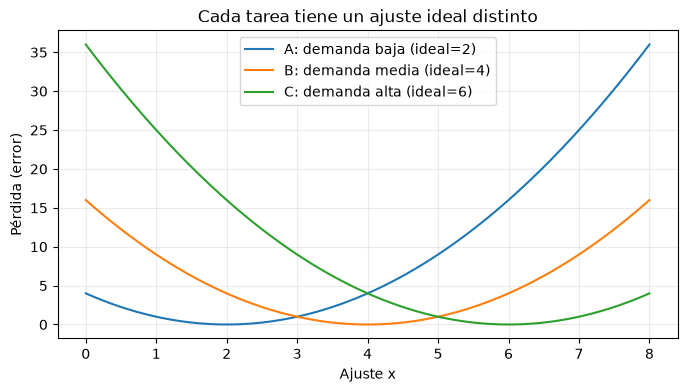

In [1]:
import numpy as np
import matplotlib.pyplot as plt
ideales = {"A: demanda baja": 2., "B: demanda media": 4., "C: demanda alta": 6.}
x = np.linspace(0, 8, 201)
plt.figure(figsize=(8,4))
for nombre, a in ideales.items():
    plt.plot(x, (x-a)**2, label=f"{nombre} (ideal={a:g})")
plt.xlabel("Ajuste x"); plt.ylabel("Pérdida (error)")
plt.title("Cada tarea tiene un ajuste ideal distinto")
plt.legend(); plt.grid(alpha=.25); plt.show()


# <span style="color:#174ea6"> 2. Adaptarse: mejorar un ajuste poco a poco</span>

Supongamos que llega la tarea C, cuyo ajuste ideal es 6, pero empezamos en $x=0$. En vez de adivinar directamente el ideal, usamos una regla sencilla:

**Nuevo ajuste = ajuste actual + la mitad de la distancia hasta el ideal.**

- Paso 0: $x=0$, error $36$.
- Paso 1: $x=3$, error $9$.
- Paso 2: $x=4.5$, error $2.25$.
- Paso 3: $x=5.25$, error $0.5625$.

¡Ya entendimos la adaptación! Cada paso reduce el error. En problemas reales no conocemos el ajuste ideal; lo estimamos a partir de datos y una función de pérdida.

In [2]:
def perdida(x, ideal):
    return (x-ideal)**2

def adaptar(x_inicial, ideal, pasos=3, fraccion=0.5):
    recorrido = [float(x_inicial)]
    for _ in range(pasos):
        nuevo = recorrido[-1] + fraccion*(ideal-recorrido[-1])
        recorrido.append(nuevo)
    return np.array(recorrido)

r = adaptar(0, 6, pasos=3)
for paso, ajuste in enumerate(r):
    print(f"Paso {paso}: ajuste={ajuste:.3f}, error={perdida(ajuste,6):.4f}")

Paso 0: ajuste=0.000, error=36.0000
Paso 1: ajuste=3.000, error=9.0000
Paso 2: ajuste=4.500, error=2.2500
Paso 3: ajuste=5.250, error=0.5625



## <span style="color:#bd232b">2.1 La misma idea, en una ecuación</span>

$$x_{k+1}=x_k+\frac12(a_\tau-x_k)$$

Lee la fórmula de izquierda a derecha: el ajuste del siguiente paso es el actual más la mitad de lo que falta para llegar al ideal.

**Conexión con descenso de gradiente:** como la derivada de $(x-a)^2$ es $2(x-a)$, esta regla coincide con descenso de gradiente usando tasa de aprendizaje $0.25$. No necesitamos derivar para ejecutar el ejemplo.

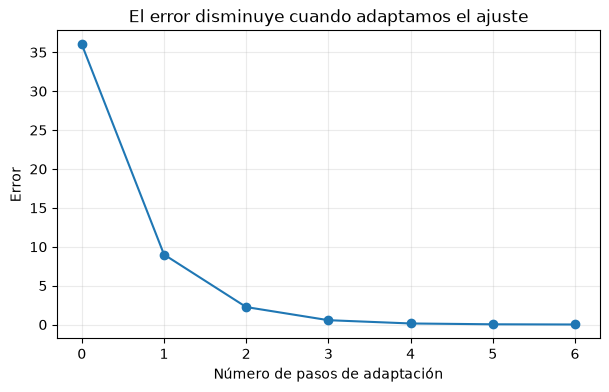

In [3]:
r = adaptar(0, 6, pasos=6)
plt.figure(figsize=(7,4))
plt.plot(range(len(r)), [perdida(v,6) for v in r], "o-")
plt.xlabel("Número de pasos de adaptación"); plt.ylabel("Error")
plt.title("El error disminuye cuando adaptamos el ajuste")
plt.xticks(range(len(r))); plt.grid(alpha=.25); plt.show()

## <span style="color:#bd232b">2.2 ¿De dónde sale el error? El controlador frente a la demanda</span>

Hasta aquí conocíamos el «ajuste ideal» de cada tarea. Pero en la práctica no lo sabemos de antemano. Lo que podemos observar es cuánto hidrocarburo transporta una configuración y compararlo con la demanda.

Construyamos otro ejemplo, independiente del anterior, para entender de dónde sale la señal de adaptación:
- Demanda: 100 m³/h.
- Un único ajuste del controlador:  $\theta$ , intensidad de bombeo.
- Modelo sintético: $Q(\theta)=20\theta$ (m³/h). No es una ecuación física de un oleoducto.
- Empezamos con $\theta=3$. El modelo predice $Q(3)=60$ m³/h.
Faltan 40 m³/h. Esto sí es un dato de desempeño que podemos usar para aprender. En el ejemplo usamos un simulador, no ensayos directos sobre una instalación real.

Pregunta de comprensión: si $\theta=4$, ¿transportamos 80 o 100 m³/h?

## <span style="color:#bd232b">2.3 Convertir el desempeño en una pérdida</span>

Definimos el error de caudal como $Q(\theta)-100$ y una pérdida que siempre es no negativa:
$$
L(\theta)=\frac{1}{2}\left(Q(\theta)-100\right)^2
=\frac{1}{2}(20\theta-100)^2
$$
El factor $1/2$ solo simplifica la derivada. Si $\theta=3$, el error es $-40$ m³/h y la pérdida vale 800. La pérdida mide qué tan lejos estamos de la demanda; no es un costo económico.

¿Cómo sabemos hacia dónde movernos? Como en este ejemplo conocemos $Q(\theta)$, calculamos su derivada:
$$
\frac{dL}{d\theta}=20(20\theta-100)
$$
En $\theta=3$, la derivada es −800: aumentar $\theta$ reduce inicialmente la pérdida. Con una tasa de aprendizaje de $\alpha=0.001$:
$$
\theta_1=3-0.001(-800)=3.8
$$
Al reevaluar, $Q(3.8)=76$ m³/h. Hemos reducido el déficit de 40 a 24 m³/h.

Importante: no estamos adivinando el ajuste ideal. Lo descubrimos gradualmente a partir de una medida de desempeño y una regla de actualización.

Paso | theta | caudal | deficit | perdida
   0 | 3.000 |  60.00 |   40.00 |  800.00
   1 | 3.800 |  76.00 |   24.00 |  288.00
   2 | 4.280 |  85.60 |   14.40 |  103.68
   3 | 4.568 |  91.36 |    8.64 |   37.32
   4 | 4.741 |  94.82 |    5.18 |   13.44
   5 | 4.844 |  96.89 |    3.11 |    4.84
   6 | 4.907 |  98.13 |    1.87 |    1.74
   7 | 4.944 |  98.88 |    1.12 |    0.63
   8 | 4.966 |  99.33 |    0.67 |    0.23
   9 | 4.980 |  99.60 |    0.40 |    0.08
  10 | 4.988 |  99.76 |    0.24 |    0.03
  11 | 4.993 |  99.85 |    0.15 |    0.01


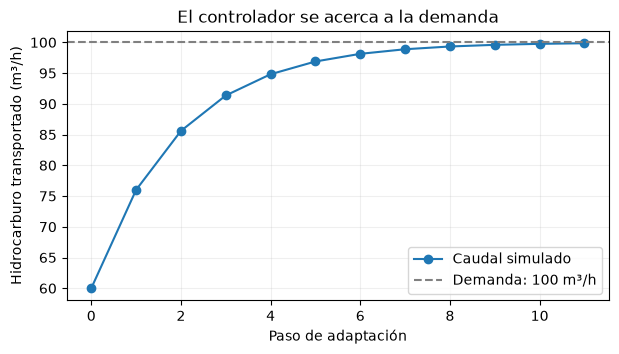

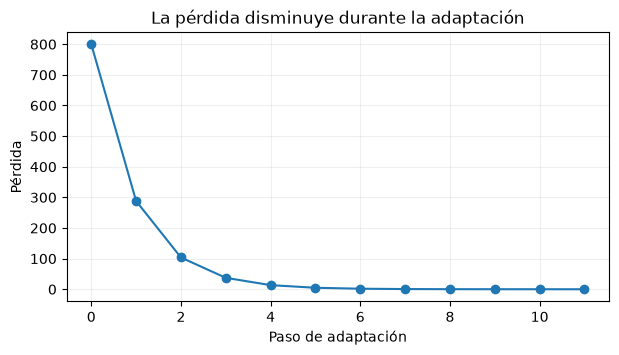

In [7]:
import numpy as np
import matplotlib.pyplot as plt

demanda = 100.0
alpha = 0.001
theta = 3.0
historial = []
for paso in range(12):
    q = 20 * theta
    error = q - demanda
    perdida = 0.5 * error**2
    historial.append((paso, theta, q, demanda-q, perdida))
    gradiente = 20 * error
    theta = theta - alpha * gradiente

print('Paso | theta | caudal | deficit | perdida')
for paso, t, q, deficit, perdida in historial:
    print(f'{paso:4d} | {t:5.3f} | {q:6.2f} | {deficit:7.2f} | {perdida:7.2f}')

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot([r[0] for r in historial], [r[2] for r in historial], 'o-', label='Caudal simulado')
ax.axhline(demanda, linestyle='--', color='gray', label='Demanda: 100 m³/h')
ax.set(xlabel='Paso de adaptación', ylabel='Hidrocarburo transportado (m³/h)', title='El controlador se acerca a la demanda')
ax.legend(); ax.grid(alpha=0.2); plt.show()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot([r[0] for r in historial], [r[4] for r in historial], 'o-')
ax.set(xlabel='Paso de adaptación', ylabel='Pérdida', title='La pérdida disminuye durante la adaptación')
ax.grid(alpha=0.2); plt.show()


## <span style="color:#bd232b">2.4 ¿Cuándo nos detenemos? ¿Y qué significa adaptar en un oleoducto?</span>

En este ejemplo decidimos antes de empezar que una configuración es aceptable cuando el déficit absoluto de transporte es menor que 1 m³/h:

$|Q(\theta)-100|<1.$

El código muestra el desempeño de cada paso. Podemos parar al alcanzar la tolerancia o un número máximo de pasos. Cumplir la demanda no demuestra que minimicemos energía ni que la operación sea segura: esos serían criterios y restricciones adicionales.

En un sistema real, no se prueban cambios arbitrarios sobre el oleoducto. Primero se evalúan en un simulador o modelo; la eventual aplicación física requiere validación, límites operativos y supervisión.

Puente hacia Reptile: todo lo anterior es adaptación a una tarea, todavía no es meta-learning. Si cambia la resistencia hidráulica o la demanda, cambia la tarea y puede cambiar la pérdida. Reptile aprende un punto inicial θ_meta para que este mismo proceso de adaptación necesite menos pasos en tareas nuevas.

En las secciones siguientes volvemos al primer juguete, con ajustes ideales 2, 4 y 6: es otra forma, más abreviada, de representar una pérdida por tarea. Ahora sabemos qué mecanismo operativo puede haber detrás de esa pérdida.

# <span style="color:#174ea6"> 3. ¿Qué significa meta-learning?</span>

Ahora queremos prepararnos **antes** de saber cuál tarea llegará. En vez de memorizar el ajuste ideal de una sola tarea, buscamos un **buen punto de partida** desde el cual podamos adaptarnos rápidamente a muchas tareas.

En nuestras tres tareas, los ideales son 2, 4 y 6. El punto medio es 4.

- Si la tarea futura es A, empezar en 4 está a 2 unidades del ideal.
- Si es B, ya estamos en el ideal.
- Si es C, estamos a 2 unidades.

Esto ilustra una **inicialización útil**. En este juguete simétrico es el promedio, pero **en general meta-learning no equivale a promediar ideales**.


## <span style="color:#bd232b">3.1 Dos niveles de aprendizaje</span>

**Aprendizaje interno:** una tarea concreta llega y adaptamos el ajuste unos pasos.

**Aprendizaje externo (meta-aprendizaje):** usamos la experiencia de muchas tareas para mejorar el punto de partida que servirá para tareas futuras.

Piensa en una persona que aprende a conducir distintos vehículos: no memoriza un único volante, sino que desarrolla habilidades para adaptarse rápidamente a uno nuevo.

# <span style="color:#174ea6">  4. Reptile: aprender un buen punto de partida</span>

Reptile es un algoritmo de meta-learning. Repite este ciclo:

1. Escoge una tarea de entrenamiento.
2. Copia el punto de partida actual.
3. Adapta la copia durante unos pasos en esa tarea.
4. Mueve **un poco** el punto de partida general hacia el ajuste adaptado.
5. Repite con otras tareas.

**Muy importante:** el ajuste general no se reemplaza completamente por el de una tarea.


## <span style="color:#bd232b">4.1 Un paso de Reptile, a mano</span>

Partimos de $x_0=0$. Escogemos la tarea C, cuyo ideal es 6.

- Adaptación interna: dos pasos con fracción 0.5: $0\to3\to4.5$.
- Movimiento externo: acercamos el punto inicial **20 %** a 4.5.
- Nuevo punto inicial: $0+0.2(4.5-0)=0.9$.

La ecuación del paso externo es:

$$x_0\leftarrow x_0+\varepsilon(x_{\tau}^{\mathrm{adaptado}}-x_0)$$

Aquí $\varepsilon=0.2$. El símbolo $\leftarrow$ significa «actualizamos el valor».

In [4]:
inicio = 0.0
ideal = 6.0
adaptado = adaptar(inicio, ideal, pasos=2)[-1]
nuevo_inicio = inicio + 0.2*(adaptado-inicio)
print(f"Inicio anterior: {inicio:g}")
print(f"Resultado de adaptación interna: {adaptado:g}")
print(f"Nuevo inicio general: {nuevo_inicio:g}")

Inicio anterior: 0
Resultado de adaptación interna: 4.5
Nuevo inicio general: 0.9



## <span style="color:#bd232b"> 4.2 Repetir el ciclo con muchas tareas</span>

Ahora ejecutaremos Reptile con los ideales 2, 4 y 6. **No hace falta entender toda la sintaxis:** sigue la variable `inicio` y observa hacia dónde se mueve.

Para que el experimento pueda reproducirse, fijamos la semilla aleatoria.

Punto de partida aprendido: 3.847


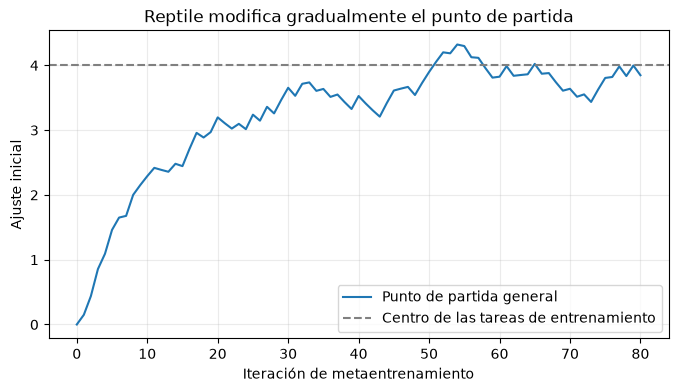

In [5]:
rng = np.random.default_rng(107)
inicio = 0.0
historia = [inicio]
ideales_entrenamiento = np.array([2.,4.,6.])
for _ in range(80):
    ideal = rng.choice(ideales_entrenamiento)
    adaptado = adaptar(inicio, ideal, pasos=2)[-1]
    inicio = inicio + 0.1*(adaptado-inicio)
    historia.append(inicio)
print(f"Punto de partida aprendido: {inicio:.3f}")
plt.figure(figsize=(8,4))
plt.plot(historia, label="Punto de partida general")
plt.axhline(4, ls="--", color="gray", label="Centro de las tareas de entrenamiento")
plt.xlabel("Iteración de metaentrenamiento"); plt.ylabel("Ajuste inicial")
plt.title("Reptile modifica gradualmente el punto de partida")
plt.legend(); plt.grid(alpha=.25); plt.show()

## <span style="color:#bd232b"> 4.3 ¿Y MAML y FOMAML?</span>

Los tres métodos buscan una inicialización que permita adaptarse con pocos ejemplos o pasos.

- **MAML:** optimiza el punto de partida teniendo en cuenta cómo cambia la pérdida después de la adaptación; puede necesitar derivadas de segundo orden.
- **FOMAML:** usa una aproximación de primer orden.
- **Reptile:** mueve el punto de partida hacia los parámetros obtenidos tras adaptar una tarea.

**Para esta lección implementamos solo Reptile.** No es necesario programar MAML para entender la idea.


# <span style="color:#174ea6"> 5. ¿Cómo comprobamos que realmente ayuda?</span>

No basta con mirar que el punto de partida cambió. Debemos comparar cuánto tarda en adaptarse a una **tarea nueva**.

Usaremos la tarea de prueba con ideal **5**, que no estuvo en la lista de entrenamiento (2, 4 y 6). Comparamos:

1. **Desde cero:** inicio 0.
2. **Transferencia de una sola tarea:** inicio 2 (aprendimos únicamente la tarea A).
3. **Meta-learning Reptile:** inicio aprendido con las tres tareas.

Los tres usarán exactamente la misma regla y el mismo número de pasos de adaptación.

Desde cero               error inicial=25.000; error final=0.0244
Transferencia (tarea A)  error inicial=9.000; error final=0.0088
Reptile                  error inicial=1.328; error final=0.0013


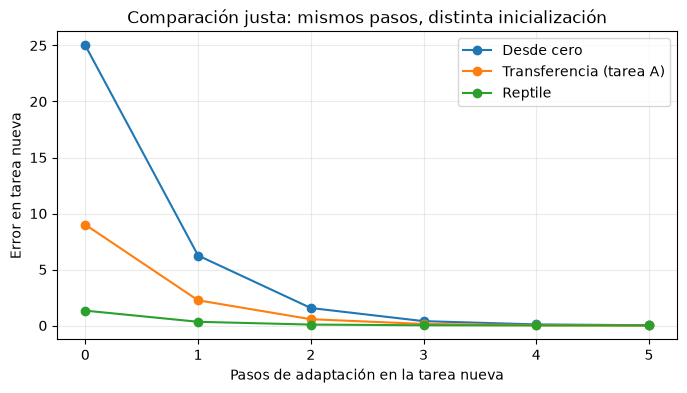

In [6]:
ideal_prueba = 5.0
inicios = {"Desde cero": 0., "Transferencia (tarea A)": 2., "Reptile": float(inicio)}
plt.figure(figsize=(8,4))
for nombre, x0 in inicios.items():
    camino = adaptar(x0, ideal_prueba, pasos=5)
    errores = [perdida(v, ideal_prueba) for v in camino]
    print(f"{nombre:24s} error inicial={errores[0]:.3f}; error final={errores[-1]:.4f}")
    plt.plot(range(len(errores)), errores, marker="o", label=nombre)
plt.xlabel("Pasos de adaptación en la tarea nueva")
plt.ylabel("Error en tarea nueva")
plt.title("Comparación justa: mismos pasos, distinta inicialización")
plt.legend(); plt.grid(alpha=.25); plt.show()


## <span style="color:#bd232b"> 5.1 Qué podemos y qué no podemos concluir</span>

En este ejemplo, Reptile puede comenzar cerca de una tarea nueva porque las tareas son parecidas y el punto inicial se entrenó para adaptarse a ellas.

**Pero no hemos demostrado** que siempre gane, ni que un método que funciona en este juguete mejore automáticamente el control de un oleoducto. En otros conjuntos de tareas, otro punto inicial puede ser mejor.

En una evaluación real debemos separar tareas de entrenamiento y prueba, usar varios escenarios de prueba, y comparar métodos con los mismos datos y presupuesto de adaptación.


## <span style="color:#bd232b">Reflexión final. ¿Por qué es tan importante el punto de partida?</span>
Hasta ahora hemos aprendido que el meta-learning busca facilitar la adaptación a nuevas tareas. Pero surge una pregunta importante: **¿por qué necesitamos aprender un buen punto inicial? ¿No bastaría con comenzar en cualquier lugar y aplicar descenso por gradiente?**

La respuesta es que no siempre.

### 1. El descenso por gradiente no siempre encuentra la mejor solución

Recordemos cómo funciona el descenso por gradiente.

Partimos de un valor inicial de los parámetros, calculamos el gradiente de la función de pérdida y damos un pequeño paso en la dirección contraria:

$$
\theta_{k+1}=\theta_k-\alpha\nabla L(\theta_k)
$$

Después actualizamos los parámetros, evaluamos nuevamente la pérdida y repetimos el procedimiento hasta satisfacer un criterio de parada.

Cuando la función de pérdida es convexa y se cumplen ciertas condiciones, este procedimiento puede conducir a un mínimo global.

Pero muchas funciones de pérdida utilizadas en aprendizaje automático **no son convexas**. Pueden tener varios mínimos locales, y el punto inicial puede influir en cuál de ellos terminamos.

<img src="../Imagenes/funcion_perdida_no_convexa.svg" width="800"/>


*Figura107A.1. Una función de pérdida no convexa puede tener varios mínimos. Dependiendo del punto inicial, el descenso por gradiente puede conducir a soluciones diferentes.*

Observemos la figura.

Si comenzamos en el punto A, el descenso por gradiente puede conducirnos al valle de la izquierda, que corresponde a un mínimo local.

Si comenzamos en B, podemos llegar al valle de la derecha, donde la pérdida es menor.

En ambos casos utilizamos el mismo algoritmo. Lo que cambia es el punto de partida.

**Esta es una de las razones por las cuales resulta tan importante aprender una buena inicialización.**

### 2. ¿Qué aporta entonces el meta-learning?

En lugar de comenzar cada nueva tarea desde un punto arbitrario, podemos aprovechar la experiencia adquirida al resolver muchas tareas anteriores.

Imaginemos que hemos aprendido a operar un sistema de transporte de hidrocarburos bajo diferentes condiciones de demanda, resistencia hidráulica y funcionamiento de las bombas.

Cada condición constituye una tarea diferente.

Al resolverlas, obtenemos información sobre qué regiones del espacio de parámetros permiten una adaptación rápida y satisfactoria.

El meta-learning intenta aprovechar esa experiencia para encontrar un punto inicial especialmente conveniente.

**No aprendemos una solución definitiva para todas las tareas. Aprendemos desde dónde conviene comenzar a buscar la solución de una tarea nueva.**

### 3. ¿Qué significa que un punto inicial sea bueno?

Un buen punto inicial no tiene que ser necesariamente el que produce la menor pérdida antes de comenzar la adaptación.

Lo importante es lo que sucede *después de unos pocos pasos de aprendizaje*.

Imaginemos dos puntos iniciales:

- Desde A necesitamos 50 actualizaciones para conseguir una solución satisfactoria.
- Desde B necesitamos solamente 5 actualizaciones para conseguir una solución igualmente satisfactoria.

En ese caso, B es más conveniente si nuestro propósito es adaptarnos rápidamente.

Esta es la idea que motiva algoritmos como Reptile.

Durante el meta-entrenamiento, Reptile utiliza distintas tareas y sus correspondientes procesos de adaptación para modificar progresivamente una inicialización compartida.

Cuando aparece una tarea nueva, comenzamos desde esa inicialización aprendida y realizamos los pasos de adaptación necesarios.

### 4. Una formulación matemática sencilla

Podemos representar el objetivo general de aprender una buena inicialización mediante:

$$
\min_{\theta_0}
\mathbb{E}_{T\sim p(T)}
\left[
L_T\left(U_T^K(\theta_0)\right)
\right]
$$

Aunque parece complicada, la expresión dice algo bastante sencillo.

- $\theta_0$ es el punto inicial que queremos aprender.
- $T$ representa una tarea.
- $p(T)$ representa la distribución de tareas que esperamos encontrar.
- $U_T^K(\theta_0)$ es el resultado de realizar $K$ pasos de adaptación desde $\theta_0$ para la tarea $T$.
- $L_T$ mide la pérdida obtenida después de esa adaptación.
- $\mathbb{E}$ representa el promedio sobre las tareas.

En palabras:

**Buscamos un punto inicial que permita obtener, en promedio, pérdidas pequeñas después de unas pocas actualizaciones en diferentes tareas.**

Esta formulación expresa el propósito general del aprendizaje de una inicialización; no significa que Reptile minimice exactamente esa expresión en cualquier situación.

### 5. ¿Garantiza el meta-learning encontrar la mejor solución?

No.

El meta-learning no elimina la no convexidad de las funciones de pérdida ni garantiza encontrar un mínimo global.

Tampoco garantiza que un punto inicial aprendido resulte conveniente para cualquier tarea imaginable.

Su utilidad depende, entre otras cosas, de que las tareas utilizadas durante el meta-entrenamiento compartan características relevantes con las nuevas tareas.

Sin embargo, puede proporcionar una ventaja importante: **reducir el esfuerzo necesario para adaptarse a condiciones nuevas**.

### 6. La idea que debemos recordar

El aprendizaje ordinario busca buenos parámetros para resolver una tarea.

El meta-learning busca aprovechar la experiencia de muchas tareas para facilitar el aprendizaje de otras.

Y cuando utilizamos meta-learning basado en inicialización, como Reptile, esa experiencia queda reflejada en un punto de partida aprendido.

**No se trata de conocer anticipadamente la solución de un problema nuevo. Se trata de haber aprendido a comenzar su búsqueda desde un lugar más favorable.**

Esa es una de las ideas centrales de *aprender a aprender*.

# <span style="color:#174ea6"> 6. ¿Qué significaría esto en Hydro-Lab?</span>

En un sistema de transporte de hidrocarburos, una tarea podría definirse por una combinación de demanda, viscosidad, capacidad disponible y estado de los equipos.

La idea sería **aprender una inicialización** de controlador o modelo que se adapte con pocas observaciones cuando cambien esas condiciones.

Nuestro ejemplo de un solo número **no implementa control hidráulico ni modifica Hydro-Lab**. Es una analogía matemática. Antes de una integración real habría que definir qué parámetros pueden adaptarse, cómo medir seguridad y desempeño, qué datos de soporte usar y cómo evaluar tareas nunca vistas.


## <span style="color:#bd232b"> 6.1 Conexión con aprendizaje por refuerzo</span>

En PPO aprendemos una política para actuar. En meta-learning nos preguntamos: **¿podemos aprender un punto de partida de la política que se adapte más rápido a nuevas condiciones?**

Son preguntas distintas y complementarias. Aquí no entrenamos PPO; únicamente ilustramos el concepto de adaptación entre tareas.


# <span style="color:#174ea6"> 7. Actividades muy sencillas</span>

**Actividad 1.** Si el ideal de una tarea es 8 y empezamos en 0, ¿cuál es el nuevo ajuste después de un paso que recorre la mitad de la distancia? **Respuesta:** 4.

**Actividad 2.** Si el punto de partida general es 2 y la adaptación termina en 6, ¿cuál es el nuevo inicio al movernos un 25 % hacia 6? **Respuesta:** 3.

**Actividad 3.** Cambia en el código el ideal de prueba de 5 a 7. ¿Qué sucede con la comparación? Explica por qué.

**Actividad 4.** En palabras: ¿cuál es la diferencia entre adaptar el controlador a una tarea y aprender a adaptarse a muchas tareas?


# <span style="color:#174ea6"> 8. Cierre y lecturas complementarias</span>

**Idea para recordar:** meta-learning no significa memorizar la solución de cada tarea. Significa aprender algo —en Reptile, una inicialización— que facilita adaptarse rápidamente a tareas nuevas.

**Lecturas para profundizar (opcionales):**
- Finn, Abbeel y Levine (2017), *Model-Agnostic Meta-Learning for Fast Adaptation of Deep Networks* (MAML).
- Nichol, Achiam y Schulman (2018), *On First-Order Meta-Learning Algorithms* (Reptile y aproximaciones de primer orden).

**Nota:** el cuaderno original 107 utiliza redes neuronales PyTorch y tareas sinusoidales con evaluación pareada. Esta versión 107A reduce deliberadamente el modelo a un solo parámetro para comprender el mecanismo antes de estudiar esa implementación avanzada.